# TAAS–제주 도로망 표본 결합 감사 / TAAS–Jeju Road Link Coverage Audit

## tl;dr

- 제주 기준 도로망에서 링크 ID 앞 3자리와 도로등급으로 층화한 **200개 링크**를 검사했다.
- TAAS 정상 레코드는 **136건(68.0%)**, 제공기관 요청 거부는 **64건**이었다.
- 정상 반환된 136개 레코드는 필수 필드가 모두 채워졌지만, 전체 커버리지 기준 90%를 통과하지 못했다.
- 정상 레코드의 위험값은 **53.7%가 0**, 중앙값 0.00, 최댓값 186.13로 긴 꼬리를 보였다.
- 따라서 TAAS는 모든 도로의 필수 입력이 아니라 **결측 상태를 보존하는 선택적 구조위험 사전정보**로 사용해야 한다.


## Context & Methods

### Key Assumptions

- 분석 단위는 `국가표준 도로 링크 1개 × TAAS 조회 1회`다.
- 링크 ID 앞 3자리는 표본 층화에만 사용하며 행정구역명으로 확정하지 않는다.
- 표본은 37,087개 기준 링크에서 `링크 앞 3자리 × 도로등급` 6개 층을 모집단 비율에 가깝게 반영했다.
- TAAS 위험도는 실시간 사고 확률이 아니라 구조적 위험 사전정보로 해석한다.
- `10 / INVALID_REQUEST_PARAMETER_ERROR`는 데이터 없음으로 바꾸지 않고 제공기관 요청 거부로 유지한다.

### Sources

- Reference network: `02_outputs/interim/molit_nodelink_jeju_20261014/jeju_links.csv`
- Audit report: `02_outputs/data/taas_coverage_audit_v0_1/audit_report.json`
- Sample outcomes: `02_outputs/data/taas_coverage_audit_v0_1/sample_results.csv`
- TAAS documentation: https://opendata.koroad.or.kr/api/selectLinkDataSet.do


## Data

In [1]:
from __future__ import annotations

import csv
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt

PROJECT_ROOT = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "PROJECT_BRIEF.md").exists()
)
AUDIT_DIR = PROJECT_ROOT / "02_outputs/data/taas_coverage_audit_v0_1"
FIGURE_DIR = PROJECT_ROOT / "02_outputs/figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

report = json.loads((AUDIT_DIR / "audit_report.json").read_text(encoding="utf-8"))
with (AUDIT_DIR / "sample_results.csv").open(encoding="utf-8", newline="") as handle:
    results = list(csv.DictReader(handle))
with (AUDIT_DIR / "road_risk_features_v0_1.csv").open(encoding="utf-8", newline="") as handle:
    features = list(csv.DictReader(handle))

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "axes.edgecolor": "#333333",
    "axes.grid": True,
    "grid.color": "#D9DEE5",
    "grid.linewidth": 0.8,
    "grid.alpha": 0.75,
})

print({
    "audit_status": report["status"],
    "sampled_links": report["summary"]["sampled_links"],
    "feature_rows": len(features),
    "failed_checks": report["failed_checks"],
})

{'audit_status': 'fail', 'sampled_links': 200, 'feature_rows': 136, 'failed_checks': ['request_success', 'record_coverage']}


## Results

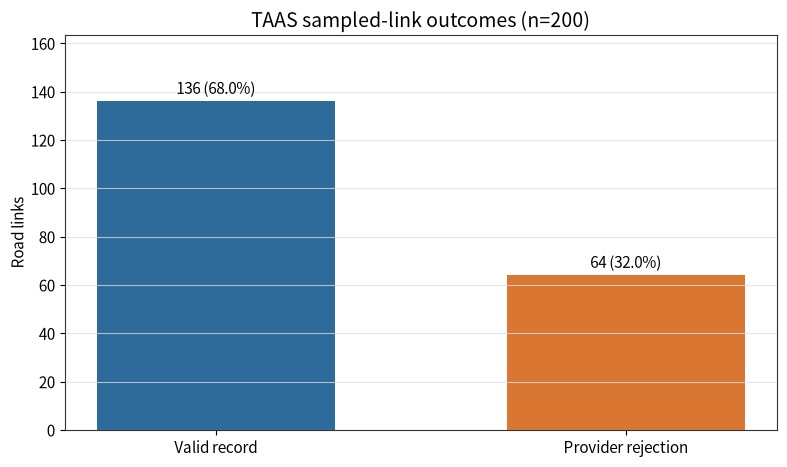

In [2]:
status_counts = report["status_counts"]
labels = ["Valid record", "Provider rejection"]
values = [status_counts.get("ok", 0), status_counts.get("api_error", 0)]
colors = ["#2F6B9A", "#D97732"]

fig, ax = plt.subplots(figsize=(8, 4.8))
bars = ax.bar(labels, values, color=colors, width=0.58)
ax.set_title("TAAS sampled-link outcomes (n=200)")
ax.set_ylabel("Road links")
ax.set_ylim(0, max(values) * 1.2)
ax.grid(axis="x", visible=False)
for bar, value in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 3, f"{value} ({value/sum(values):.1%})", ha="center")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "20261026_taas_sample_outcomes_v0_1.png", dpi=180, bbox_inches="tight")
plt.show()

정상 응답 레코드의 필드 완전성은 높지만 제공기관 거부를 포함한 전체 링크 커버리지는 별도 문제다. 두 지표를 합쳐서 해석하면 안 된다.

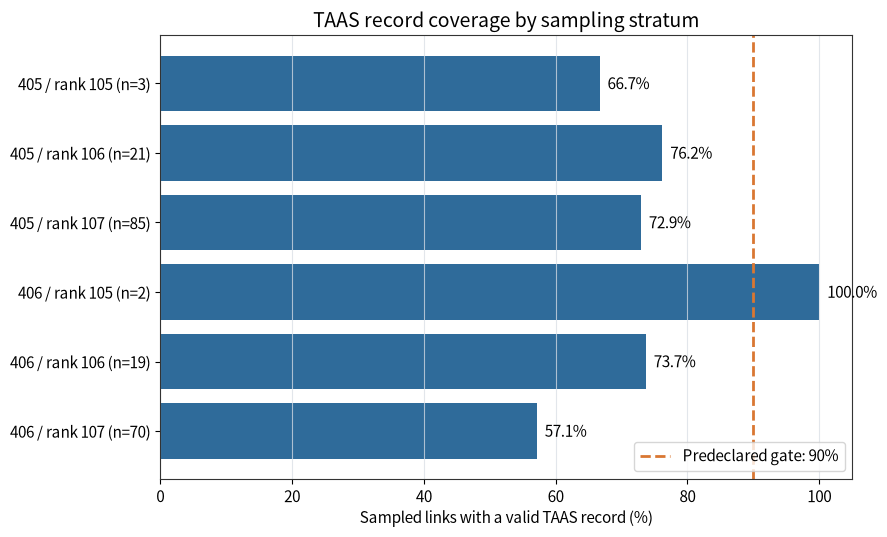

In [3]:
segments = report["segment_breakdown"]
segment_labels = [f"{row['administrative_prefix']} / rank {row['road_rank']} (n={row['sample_count']})" for row in segments]
segment_rates = [row["record_coverage_rate"] * 100 for row in segments]

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(segment_labels, segment_rates, color="#2F6B9A")
ax.axvline(90, color="#D97732", linewidth=2, linestyle="--", label="Predeclared gate: 90%")
ax.set_title("TAAS record coverage by sampling stratum")
ax.set_xlabel("Sampled links with a valid TAAS record (%)")
ax.set_xlim(0, 105)
ax.invert_yaxis()
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
for bar, value in zip(bars, segment_rates):
    ax.text(value + 1.2, bar.get_y() + bar.get_height() / 2, f"{value:.1f}%", va="center")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "20261026_taas_coverage_by_stratum_v0_1.png", dpi=180, bbox_inches="tight")
plt.show()

`406 / rank 107` 층의 관측 커버리지가 가장 낮지만, 앞 3자리 코드를 행정구역명으로 확정하지 않았고 표본 결과이므로 원인을 지역 효과로 단정하지 않는다.

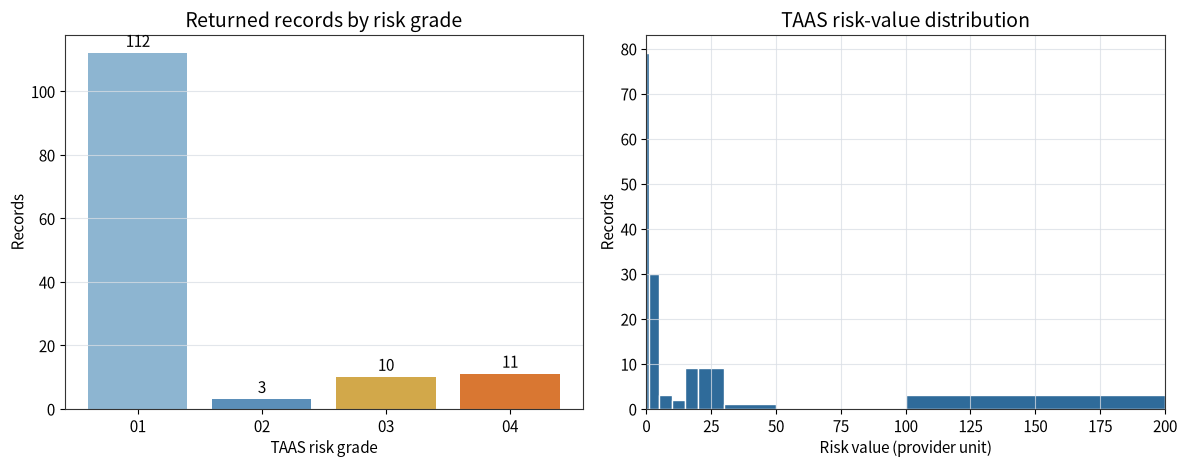

{'01': {'count': 112, 'minimum': 0.0, 'median': 0.0, 'maximum': 15.77},
 '02': {'count': 3, 'minimum': 9.06, 'median': 11.67, 'maximum': 12.59},
 '03': {'count': 10, 'minimum': 17.59, 'median': 19.46, 'maximum': 24.0},
 '04': {'count': 11, 'minimum': 20.57, 'median': 29.52, 'maximum': 186.13}}

In [4]:
grade_summary = report["risk_distribution"]["grade_value_summary"]
grades = sorted(grade_summary)
grade_counts = [grade_summary[grade]["count"] for grade in grades]
risk_values = [float(row["structural_risk_value"]) for row in features]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
grade_bars = axes[0].bar(grades, grade_counts, color=["#8DB5D1", "#5B8FB9", "#D2A84A", "#D97732"])
axes[0].set_title("Returned records by risk grade")
axes[0].set_xlabel("TAAS risk grade")
axes[0].set_ylabel("Records")
axes[0].grid(axis="x", visible=False)
for bar, value in zip(grade_bars, grade_counts):
    axes[0].text(bar.get_x() + bar.get_width() / 2, value + 2, str(value), ha="center")

bins = [0, 1, 5, 10, 15, 20, 30, 50, 100, 200]
axes[1].hist(risk_values, bins=bins, color="#2F6B9A", edgecolor="white")
axes[1].set_title("TAAS risk-value distribution")
axes[1].set_xlabel("Risk value (provider unit)")
axes[1].set_ylabel("Records")
axes[1].set_xlim(0, 200)

fig.tight_layout()
fig.savefig(FIGURE_DIR / "20261026_taas_risk_distribution_v0_1.png", dpi=180, bbox_inches="tight")
plt.show()

grade_summary

## Takeaways

1. **High severity, high confidence — coverage gate failed.** 200개 중 136개(68.0%)만 정상 레코드를 반환했다. 사전 기준 90%에 못 미치므로 TAAS를 모든 도로의 필수 위험 피처로 사용하면 표본의 32.0%가 누락된다.
2. **High severity, high confidence — provider rejection is distinct from missing data.** 64건은 모두 HTTP 200 내부의 `10 / INVALID_REQUEST_PARAMETER_ERROR`였고 재호출에서도 반복됐다. 이를 위험도 0이나 데이터 없음으로 대체하지 않는다.
3. **Low severity, high confidence — returned schema is stable.** 정상 반환된 136개는 `index`, `line_string`, `anals_value`, `anals_grd` 필드가 모두 채워졌다.
4. **Medium modeling risk — distribution is zero-inflated and long-tailed.** 위험값의 53.7%가 0이고 중앙값은 0.00, 최댓값은 186.13다. 평균 기반 단순 정규화보다 강건한 변환과 등급 병행이 필요하다.

### Recommended use

- TAAS는 `available / rejected / unavailable` 상태를 함께 보존하는 선택적 구조위험 피처로 사용한다.
- TAAS 미수록·거부 구간은 국가표준 도로 속성, 기상청 정보, 향후 C-ITS·ITS로 보완한다.
- TAAS 제공기관에 코드 10의 정확한 의미, 지원 좌표 범위, 기준 도로망 버전을 문의한 뒤 커버리지 게이트를 재실행한다.
